In [ ]:
from google.colab import userdata
from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import cross_val_score, StratifiedKFold
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import urllib.request
import time
import os
import gc

# Configurações do GIT
token = userdata.get('GITHUB_TOKEN')
usuario = "muriloklein"
repo = "tcc"

if not os.path.exists("/content/tcc"):
    !git clone https://{token}@github.com/{usuario}/{repo}.git
%cd /content/tcc

# !git config --global user.email "eu.murilok@gmail.com"
# !git config --global user.name "Murilo Klein"

# !pip install imbalanced-learn --quiet

/content/tcc


In [ ]:
# Montar o Google Drive
drive.mount('/content/drive')

# Cria a pasta onde os dados brutos vão ficar (se ainda não existir)
DADOS_DIR = "/content/drive/MyDrive/TCC/dados/raw"
os.makedirs(DADOS_DIR, exist_ok=True)

print(f"Pasta de dados pronta em: {DADOS_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Pasta de dados pronta em: /content/drive/MyDrive/TCC/dados/raw


In [ ]:
# Baixar os arquivos conn.log.labeled dos cenários escolhidos
cenarios = {
    "capture_34_1_DDoS_PortScan": (
        "https://mcfp.felk.cvut.cz/publicDatasets/IoT-23-Dataset/"
        "IndividualScenarios/CTU-IoT-Malware-Capture-34-1/bro/conn.log.labeled"
    ),
    "capture_9_1_PortScan": (
        "https://mcfp.felk.cvut.cz/publicDatasets/IoT-23-Dataset/"
        "IndividualScenarios/CTU-IoT-Malware-Capture-9-1/bro/conn.log.labeled"
    ),
    "capture_36_1_Okiru": (
        "https://mcfp.felk.cvut.cz/publicDatasets/IoT-23-Dataset/"
        "IndividualScenarios/CTU-IoT-Malware-Capture-36-1/bro/conn.log.labeled"
    ),
    "capture_4_1_Benign_Honeypot": (
        "https://mcfp.felk.cvut.cz/publicDatasets/IoT-23-Dataset/"
        "IndividualScenarios/CTU-Honeypot-Capture-4-1/bro/conn.log.labeled"
    ),
    "capture_5_1_Benign_Honeypot": (
      "https://mcfp.felk.cvut.cz/publicDatasets/IoT-23-Dataset/"
      "IndividualScenarios/CTU-Honeypot-Capture-5-1/bro/conn.log.labeled"
    ),
    "capture_7_1_Benign_Honeypot": (
      "https://mcfp.felk.cvut.cz/publicDatasets/IoT-23-Dataset/"
      "IndividualScenarios/CTU-Honeypot-Capture-7-1/Somfy-01/bro/conn.log.labeled"
    ),
}

for nome, url in cenarios.items():
    destino = os.path.join(DADOS_DIR, f"{nome}.log.labeled")

    # Se baixado antes, não baixa de novo
    if os.path.exists(destino):
        print(f"[OK] {nome} já existe, pulando download.")
        continue

    print(f"Baixando {nome}...")
    try:
        urllib.request.urlretrieve(url, destino)
        print(f"[OK] {nome} salvo em {destino}")
    except Exception as e:
        print(f"[ERRO] Falha ao baixar {nome}: {e}")

[OK] capture_34_1_DDoS_PortScan já existe, pulando download.
[OK] capture_9_1_PortScan já existe, pulando download.
[OK] capture_36_1_Okiru já existe, pulando download.
[OK] capture_4_1_Benign_Honeypot já existe, pulando download.
[OK] capture_5_1_Benign_Honeypot já existe, pulando download.
[OK] capture_7_1_Benign_Honeypot já existe, pulando download.


In [ ]:
# Carregar o arquivo corretamente com pandas
colunas_usadas = [
    "id.orig_p", "id.resp_p", "proto", "service", "duration",
    "orig_bytes", "resp_bytes", "conn_state", "local_orig", "local_resp",
    "missed_bytes", "history", "orig_pkts", "orig_ip_bytes",
    "resp_pkts", "resp_ip_bytes", "label", "detailed-label"
]

# Nomes de coluna padrão do conn.log do Zeek + as 2 colunas extras do IoT-23.
colunas_completas = [
    "ts", "uid", "id.orig_h", "id.orig_p", "id.resp_h", "id.resp_p",
    "proto", "service", "duration", "orig_bytes", "resp_bytes",
    "conn_state", "local_orig", "local_resp", "missed_bytes",
    "history", "orig_pkts", "orig_ip_bytes", "resp_pkts", "resp_ip_bytes",
    "tunnel_parents", "label", "detailed-label"
]

caminho_34 = os.path.join(DADOS_DIR, "capture_34_1_DDoS_PortScan.log.labeled")
caminho_36 = os.path.join(DADOS_DIR, "capture_36_1_Okiru.log.labeled")
caminho_5_1 = os.path.join(DADOS_DIR, "capture_5_1_Benign_Honeypot.log.labeled")
caminho_4_1 = os.path.join(DADOS_DIR, "capture_4_1_Benign_Honeypot.log.labeled")
caminho_9_1 = os.path.join(DADOS_DIR, "capture_9_1_PortScan.log.labeled")
caminho_7_1 = os.path.join(DADOS_DIR, "capture_7_1_Benign_Honeypot.log.labeled")

# dtype otimizado: colunas repetitivas viram 'category' (muito mais leve que string/object)
# e colunas numéricas usam tipos menores (int32 em vez de int64/float64)
dtype_otimizado = {
    "proto": "category",
    "service": "category",
    "conn_state": "category",
    "local_orig": "category",
    "local_resp": "category",
    "history": "category",
    "label": "category",
    "detailed-label": "category",
    "id.orig_p": "int32",
    "id.resp_p": "int32",
    "missed_bytes": "int32",
    "orig_pkts": "int32",
    "orig_ip_bytes": "int32",
    "resp_pkts": "int32",
    "resp_ip_bytes": "int32",
}

config = {
    "sep": r"\s+", # colunas separadas por espaço/tab (o header usa \x09; Mas as últimas colunas às vezes vêm separadas por espaço simples - \s+ lida com os dois casos)
    "comment": "#", # ignora todas as linhas de cabeçalho que começam com #
    "header": None, # não tem cabeçalho "normal" de CSV, vamos nomear na mão
    "names": colunas_completas, # nomes de todas as colunas do arquivo
    "usecols": colunas_usadas, # mas só carrega estas na memória
    "na_values": "-", # o Zeek usa "-" para representar valor ausente
    "dtype": dtype_otimizado, # <-- reduz drasticamente o uso de RAM
}

In [ ]:
# Função utilitária: carrega um cenário já otimizado e imprime um resumo
def carregar_cenario(caminho, nome_origem, filtro_excluir_detailed_label=None):
    df = pd.read_csv(caminho, **config)

    # 'label' e 'detailed-label' já vêm como category; padroniza para minúsculo
    df["label"] = df["label"].astype("string").str.lower().astype("category")
    df["detailed-label"] = df["detailed-label"].astype("string").str.lower().astype("category")

    if filtro_excluir_detailed_label is not None:
        df = df[df["detailed-label"] != filtro_excluir_detailed_label]

    df["origem_cenario"] = nome_origem

    print(f"Formato do DataFrame ({nome_origem}): {df.shape}")
    print(f"Uso de memória: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
    print(df["label"].value_counts())
    print("-" * 60)

    return df

In [ ]:
df_34 = carregar_cenario(caminho_34, "capture_34_1")

Formato do DataFrame (capture_34_1): (23145, 19)
Uso de memória: 2.67 MB
label
malicious    21222
benign        1923
Name: count, dtype: int64
------------------------------------------------------------


In [ ]:
df_36 = carregar_cenario(caminho_36, "capture_36_1", filtro_excluir_detailed_label="okiru-attack")

Formato do DataFrame (capture_36_1): (13645095, 19)
Uso de memória: 1678.68 MB
label
malicious    13642432
benign           2663
Name: count, dtype: int64
------------------------------------------------------------


In [ ]:
df_5_1 = carregar_cenario(caminho_5_1, "capture_5_1")

Formato do DataFrame (capture_5_1): (1374, 19)
Uso de memória: 0.16 MB
label
benign    1374
Name: count, dtype: int64
------------------------------------------------------------


In [ ]:
df_4_1 = carregar_cenario(caminho_4_1, "capture_4_1")

Formato do DataFrame (capture_4_1): (452, 19)
Uso de memória: 0.05 MB
label
benign    452
Name: count, dtype: int64
------------------------------------------------------------


In [ ]:
df_9_1 = carregar_cenario(caminho_9_1, "capture_9_1")

Formato do DataFrame (capture_9_1): (6378293, 19)
Uso de memória: 729.94 MB
label
malicious    6355745
benign         22548
Name: count, dtype: int64
------------------------------------------------------------


In [ ]:
df_7_1 = carregar_cenario(caminho_7_1, "capture_7_1")

Formato do DataFrame (capture_7_1): (130, 19)
Uso de memória: 0.02 MB
label
benign    130
Name: count, dtype: int64
------------------------------------------------------------


In [ ]:
# Une todos em um único DataFrame, empilhando as linhas
df_completo = pd.concat(
    [df_34, df_36, df_9_1, df_4_1, df_5_1, df_7_1],
    ignore_index=True   # gera um novo índice sequencial, em vez de repetir os índices originais
)

# Libera a memória dos DataFrames individuais
del df_34, df_36, df_9_1, df_4_1, df_5_1, df_7_1
gc.collect()

print(f"Formato final: {df_completo.shape}")
print(f"Uso de memória total: {df_completo.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print(df_completo["origem_cenario"].value_counts())
print(df_completo["label"].value_counts())

Formato final: (20048489, 19)
Uso de memória total: 7992.63 MB
origem_cenario
capture_36_1    13645095
capture_9_1      6378293
capture_34_1       23145
capture_5_1         1374
capture_4_1          452
capture_7_1          130
Name: count, dtype: int64
label
malicious    20019399
benign          29090
Name: count, dtype: Int64


In [ ]:
# Cria uma coluna auxiliar só para a amostragem,
# e para linhas benignas (que têm detailed-label vazio) usa "benign" como rótulo do grupo
df_completo["classe_amostra"] = (
    df_completo["detailed-label"]
    .astype("string")
    .fillna("benign")
)

print(df_completo["classe_amostra"].value_counts())

classe_amostra
okiru                        13626744
partofahorizontalportscan     6355867
benign                          29090
c&c-heartbeat                   15688
ddos                            14394
c&c                              6706
Name: count, dtype: Int64


In [ ]:
# Corte para amostragem das categorias
CAP_POR_CLASSE = 20000
RANDOM_STATE = 42
CLASSES_SEM_TETO = {"benign"}   # não corta o benigno, mesmo acima do teto

# CORREÇÃO (pós-diagnóstico de duplicatas): a ordem original era
# "amostrar 20.000 linhas aleatórias -> deduplicar depois". Isso é
# perigoso quando a distribuição de padrões dentro de uma classe é muito
# desigual (poucos padrões dominando o volume): a amostra aleatória tende
# a pegar quase só repetições dos padrões mais comuns, descartando por
# sorteio a diversidade real que existia nos dados brutos (foi o que
# aconteceu com 'okiru': 621 combinações únicas em 13,6 milhões de linhas
# brutas, mas a amostra de 20.000 colapsou para só 2 únicas).
#
# Correção: deduplicar DENTRO de cada classe PRIMEIRO, e só depois aplicar
# o teto de amostragem sobre o conjunto já único. Assim, se uma classe tem
# menos linhas únicas que o teto (caso do okiru), ela entra inteira.

# Colunas que definem uma linha como "duplicata exata": tudo, exceto os
# rótulos e o metadado de rastreio (mesma lógica aplicada mais adiante,
# na Etapa 2, sobre o X final — aqui é só adiantada para não perder
# diversidade real por causa da ordem das operações).
colunas_para_dedup = [
    col for col in df_completo.columns
    if col not in ["label", "detailed-label", "origem_cenario", "classe_amostra"]
]

grupos_amostrados = []
resumo_dedup = []

for classe, grupo in df_completo.groupby("classe_amostra", observed=True):
    linhas_brutas = len(grupo)

    # Deduplica antes de decidir se precisa cortar
    grupo = grupo.drop_duplicates(subset=colunas_para_dedup, keep="first")
    linhas_unicas = len(grupo)

    if classe not in CLASSES_SEM_TETO and linhas_unicas > CAP_POR_CLASSE:
        grupo = grupo.sample(n=CAP_POR_CLASSE, random_state=RANDOM_STATE)

    resumo_dedup.append({
        "classe": classe,
        "linhas_brutas": linhas_brutas,
        "linhas_unicas": linhas_unicas,
        "linhas_amostradas": len(grupo),
    })
    grupos_amostrados.append(grupo)

df_amostrado = pd.concat(grupos_amostrados, ignore_index=True)
df_amostrado = df_amostrado.drop(columns=["classe_amostra"])

del df_completo
import gc; gc.collect()

print("Resumo da deduplicação por classe (ANTES da amostragem):")
print(pd.DataFrame(resumo_dedup).to_string(index=False))
print(f"\nFormato após dedup + amostragem: {df_amostrado.shape}")
print(df_amostrado["detailed-label"].value_counts(dropna=False))
print(f"Uso de memória: {df_amostrado.memory_usage(deep=True).sum() / 1024**2:.2f} MB")


Resumo da deduplicação por classe (ANTES da amostragem):
                   classe  linhas_brutas  linhas_unicas  linhas_amostradas
                   benign          29090          22433              22433
                      c&c           6706           6706               6706
            c&c-heartbeat          15688          15687              15687
                     ddos          14394            224                224
                    okiru       13626744            621                621
partofahorizontalportscan        6355867         131593              20000

Formato após dedup + amostragem: (65671, 19)
detailed-label
<NA>                         22433
partofahorizontalportscan    20000
c&c-heartbeat                15687
c&c                           6706
okiru                          621
ddos                           224
Name: count, dtype: Int64
Uso de memória: 26.35 MB


In [ ]:
# Checkpoint
PROCESSED_DIR = "/content/drive/MyDrive/TCC/dados/processed"
os.makedirs(PROCESSED_DIR, exist_ok=True)

caminho_checkpoint = os.path.join(PROCESSED_DIR, "dataset_amostrado_v1.parquet")
df_amostrado.to_parquet(caminho_checkpoint, index=False)

print(f"Checkpoint salvo em: {caminho_checkpoint}")
print(f"Tamanho do arquivo: {os.path.getsize(caminho_checkpoint) / 1024**2:.2f} MB")

Checkpoint salvo em: /content/drive/MyDrive/TCC/dados/processed/dataset_amostrado_v1.parquet
Tamanho do arquivo: 0.69 MB


In [ ]:
caminho_checkpoint = os.path.join(PROCESSED_DIR, "dataset_amostrado_v1.parquet")
df_amostrado = pd.read_parquet(caminho_checkpoint)

print(f"Formato recarregado: {df_amostrado.shape}")
print(df_amostrado["detailed-label"].value_counts(dropna=False))

Formato recarregado: (65671, 19)
detailed-label
<NA>                         22433
partofahorizontalportscan    20000
c&c-heartbeat                15687
c&c                           6706
okiru                          621
ddos                           224
Name: count, dtype: Int64


In [ ]:
# Tratamento de valores ausentes

# Descarta colunas 100% vazias
df_amostrado = df_amostrado.drop(columns=["local_orig", "local_resp"])

# Cria indicadores antes de preencher
for col in ["duration", "orig_bytes", "resp_bytes"]:
    df_amostrado[f"{col}_ausente"] = df_amostrado[col].isna()

# Preenche os numéricos ausentes com 0
df_amostrado[["duration", "orig_bytes", "resp_bytes"]] = (
    df_amostrado[["duration", "orig_bytes", "resp_bytes"]].fillna(0)
)

# Preenche categóricas ausentes com rótulo explícito
for col in ["service", "history"]:
    if df_amostrado[col].dtype.name == "category":
        df_amostrado[col] = df_amostrado[col].cat.add_categories(["desconhecido"])
    df_amostrado[col] = df_amostrado[col].fillna("desconhecido")

print(df_amostrado.isna().sum())

id.orig_p                 0
id.resp_p                 0
proto                     0
service                   0
duration                  0
orig_bytes                0
resp_bytes                0
conn_state                0
missed_bytes              0
history                   0
orig_pkts                 0
orig_ip_bytes             0
resp_pkts                 0
resp_ip_bytes             0
label                     0
detailed-label        22433
origem_cenario            0
duration_ausente          0
orig_bytes_ausente        0
resp_bytes_ausente        0
dtype: int64


In [ ]:
# Remove colunas redundantes identificadas na EDA (correlação = 1.00 com resp_bytes/orig_bytes)
df_amostrado = df_amostrado.drop(columns=["resp_ip_bytes", "orig_ip_bytes"])

print(f"Formato após remoção: {df_amostrado.shape}")
print(df_amostrado.columns.tolist())

Formato após remoção: (65671, 18)
['id.orig_p', 'id.resp_p', 'proto', 'service', 'duration', 'orig_bytes', 'resp_bytes', 'conn_state', 'missed_bytes', 'history', 'orig_pkts', 'resp_pkts', 'label', 'detailed-label', 'origem_cenario', 'duration_ausente', 'orig_bytes_ausente', 'resp_bytes_ausente']


In [ ]:
# Checkpoint
caminho_checkpoint_limpo = os.path.join(PROCESSED_DIR, "dataset_limpo_v1.parquet")
df_amostrado.to_parquet(caminho_checkpoint_limpo, index=False)
print(f"Checkpoint salvo em: {caminho_checkpoint_limpo}")

Checkpoint salvo em: /content/drive/MyDrive/TCC/dados/processed/dataset_limpo_v1.parquet


In [ ]:
# Agrupando categorias

# Define o corte
LIMIAR_MINIMO = 500

contagem = df_amostrado["history"].value_counts()
categorias_frequentes = contagem[contagem >= LIMIAR_MINIMO].index.tolist()

print(f"Categorias mantidas ({len(categorias_frequentes)}): {categorias_frequentes}")
print(f"Categorias agrupadas em 'outros': {df_amostrado['history'].nunique() - len(categorias_frequentes)}")

# Quem não está na lista de frequentes vira "outros"
df_amostrado["history"] = df_amostrado["history"].astype("string")
df_amostrado["history"] = df_amostrado["history"].where(
    df_amostrado["history"].isin(categorias_frequentes),
    "outros"
)

print(df_amostrado["history"].value_counts())

Categorias mantidas (5): ['S', 'D', 'Sr', 'Dd', 'ShAdDaf']
Categorias agrupadas em 'outros': 107
history
S          40977
D          14009
Sr          4622
Dd          3040
outros      1546
ShAdDaf     1477
Name: count, dtype: Int64


In [ ]:
# One hot encoding
colunas_para_onehot = ["proto", "service", "conn_state", "history"]

# label e detailed-label não devem passar por one-hot — eles são os alvos que o modelo vai tentar prever (y),
# não características de entrada (X). Da mesma forma, origem_cenario continua fora (é metadado de rastreio, não feature).

df_encoded = pd.get_dummies(
    df_amostrado,
    columns=colunas_para_onehot,
    prefix=colunas_para_onehot, # prefixo nas novas colunas, ex: proto_tcp, service_dns
    dtype="int8" # 0/1 como número pequeno, economiza memória
)

print(f"Formato antes: {df_amostrado.shape}")
print(f"Formato depois: {df_encoded.shape}")
print(df_encoded.columns.tolist())

Formato antes: (65671, 18)
Formato depois: (65671, 42)
['id.orig_p', 'id.resp_p', 'duration', 'orig_bytes', 'resp_bytes', 'missed_bytes', 'orig_pkts', 'resp_pkts', 'label', 'detailed-label', 'origem_cenario', 'duration_ausente', 'orig_bytes_ausente', 'resp_bytes_ausente', 'proto_icmp', 'proto_tcp', 'proto_udp', 'service_desconhecido', 'service_dhcp', 'service_dns', 'service_http', 'service_irc', 'service_ssl', 'conn_state_OTH', 'conn_state_REJ', 'conn_state_RSTO', 'conn_state_RSTOS0', 'conn_state_RSTR', 'conn_state_RSTRH', 'conn_state_S0', 'conn_state_S1', 'conn_state_S2', 'conn_state_S3', 'conn_state_SF', 'conn_state_SH', 'conn_state_SHR', 'history_D', 'history_Dd', 'history_S', 'history_ShAdDaf', 'history_Sr', 'history_outros']


In [ ]:
# Checkpoint
caminho_checkpoint_encoded = os.path.join(PROCESSED_DIR, "dataset_encoded_v1.parquet")
df_encoded.to_parquet(caminho_checkpoint_encoded, index=False)
print(f"Checkpoint salvo em: {caminho_checkpoint_encoded}")

Checkpoint salvo em: /content/drive/MyDrive/TCC/dados/processed/dataset_encoded_v1.parquet


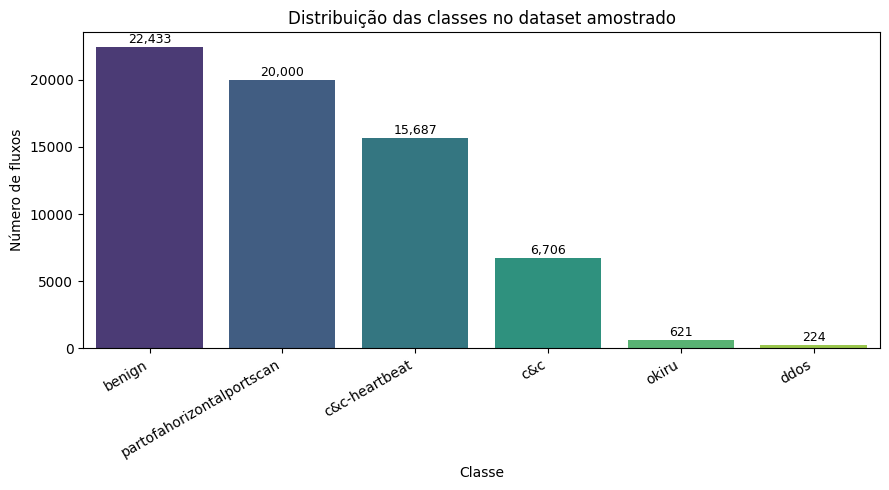

In [ ]:
# Gráfico 1 — Distribuição de classes
contagem_classes = df_amostrado["detailed-label"].astype("string").fillna("benign").value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(x=contagem_classes.index, y=contagem_classes.values, hue=contagem_classes.index, palette="viridis", legend=False)
plt.title("Distribuição das classes no dataset amostrado")
plt.xlabel("Classe")
plt.ylabel("Número de fluxos")
plt.xticks(rotation=30, ha="right")

for i, valor in enumerate(contagem_classes.values):
    plt.text(i, valor + 300, f"{valor:,}", ha="center", fontsize=9)

plt.tight_layout()

FIGURAS_DIR = "/content/drive/MyDrive/TCC/resultados/figuras"
os.makedirs(FIGURAS_DIR, exist_ok=True)
plt.savefig(os.path.join(FIGURAS_DIR, "distribuicao_classes.png"), dpi=300, bbox_inches="tight")

plt.show()

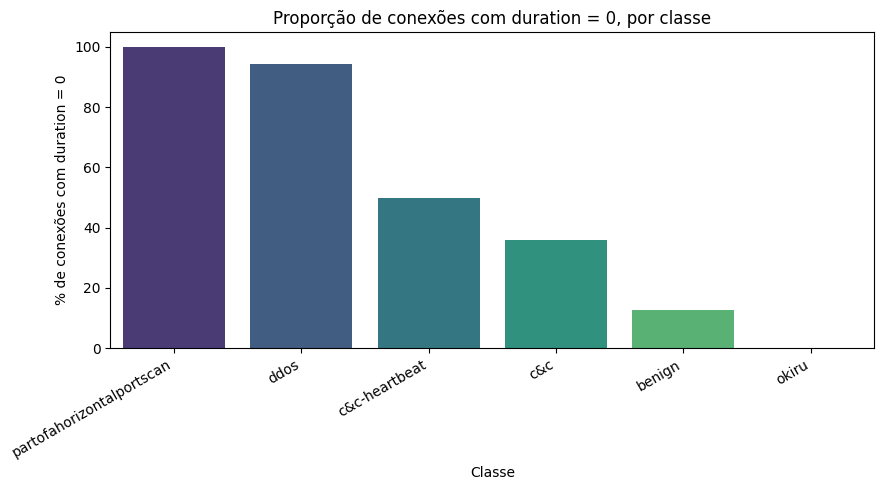

In [ ]:
# Gráfico 2a — Proporção de conexões "instantâneas" (duration = 0) por classe
df_plot = df_amostrado.copy()
df_plot["classe_plot"] = df_plot["detailed-label"].astype("string").fillna("benign")

df_plot["duration_zero"] = df_plot["duration"] == 0

proporcao_zero = df_plot.groupby("classe_plot", observed=True)["duration_zero"].mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=proporcao_zero.index, y=proporcao_zero.values * 100, hue=proporcao_zero.index, palette="viridis", legend=False)
plt.title("Proporção de conexões com duration = 0, por classe")
plt.xlabel("Classe")
plt.ylabel("% de conexões com duration = 0")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(FIGURAS_DIR, "proporcao_duration_zero.png"), dpi=300, bbox_inches="tight")
plt.show()

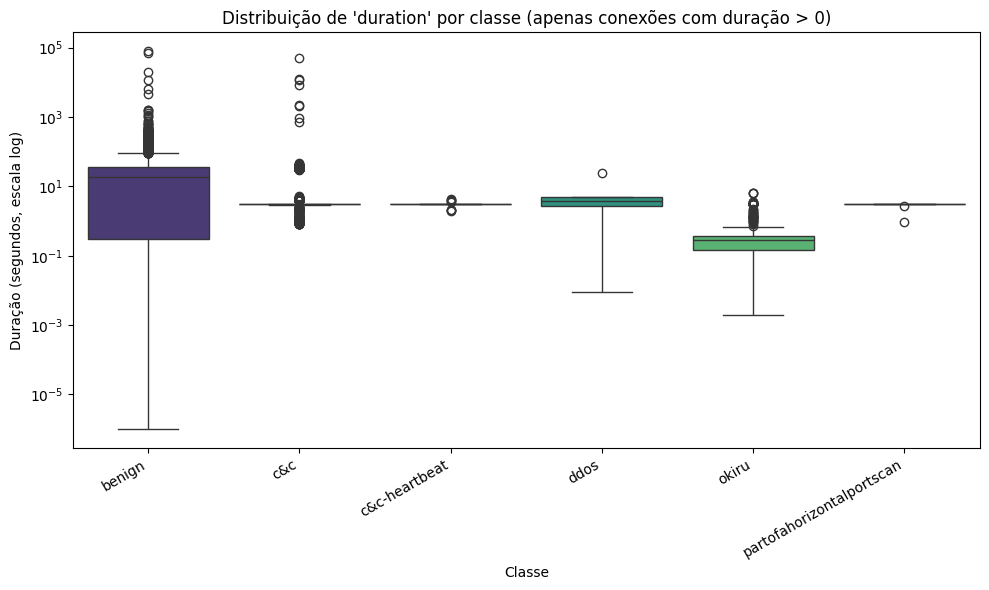

In [ ]:
# Gráfico 2b — O boxplot original, mas só com quem tem duração real (> 0)
df_com_duracao = df_plot[df_plot["duration"] > 0]

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_com_duracao, x="classe_plot", y="duration", hue="classe_plot", palette="viridis", legend=False)
plt.yscale("log")
plt.title("Distribuição de 'duration' por classe (apenas conexões com duração > 0)")
plt.xlabel("Classe")
plt.ylabel("Duração (segundos, escala log)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(FIGURAS_DIR, "duration_por_classe_sem_zeros.png"), dpi=300, bbox_inches="tight")
plt.show()

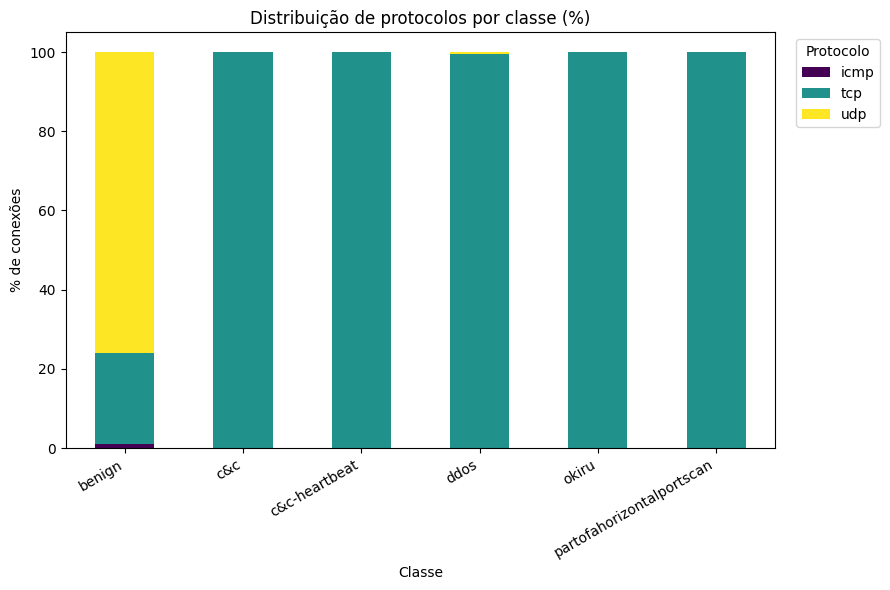

In [ ]:
# Gráfico 3 — Protocolos por classe
tabela_proto = pd.crosstab(df_plot["classe_plot"], df_plot["proto"], normalize="index") * 100

plt.figure(figsize=(9, 6))
tabela_proto.plot(kind="bar", stacked=True, colormap="viridis", ax=plt.gca())
plt.title("Distribuição de protocolos por classe (%)")
plt.xlabel("Classe")
plt.ylabel("% de conexões")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Protocolo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(FIGURAS_DIR, "protocolo_por_classe.png"), dpi=300, bbox_inches="tight")
plt.show()

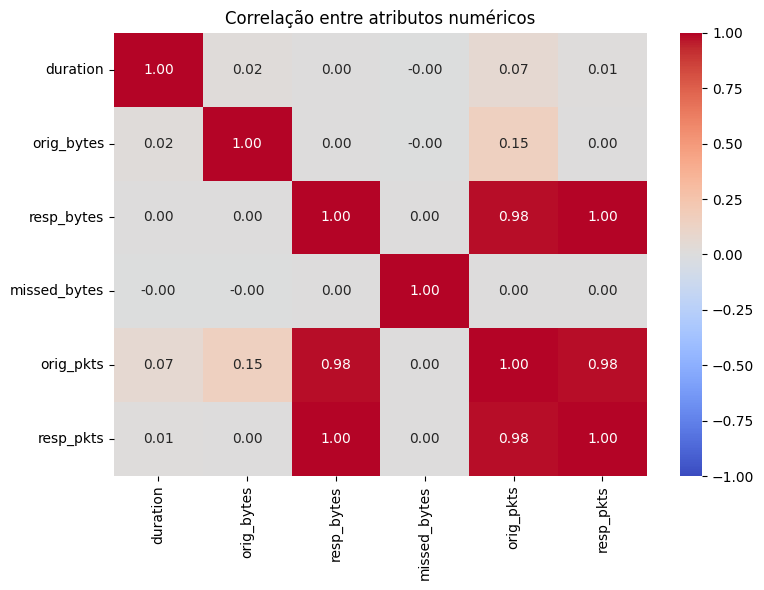

In [ ]:
# Matriz de correlação
colunas_numericas = [
    "duration", "orig_bytes", "resp_bytes", "missed_bytes",
    "orig_pkts", "resp_pkts",
]

matriz_corr = df_amostrado[colunas_numericas].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlação entre atributos numéricos")
plt.tight_layout()
plt.savefig(os.path.join(FIGURAS_DIR, "correlacao_numericos.png"), dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Carrega o checkpoint mais recente
df_encoded = pd.read_parquet(os.path.join(PROCESSED_DIR, "dataset_encoded_v1.parquet"))

# Colunas que NÃO são features (não entram no X):
# - label, detailed-label -> são os alvos (y), não entradas
# - origem_cenario -> metadado de rastreio, causaria vazamento
colunas_nao_feature = ["label", "detailed-label", "origem_cenario"]

X = df_encoded.drop(columns=colunas_nao_feature)

y_binario = df_encoded["label"]  # "benign" / "malicious"

# Para multiclasse: usa detailed-label, preenchendo os NaN (benignos) com "benign"
y_multiclasse = df_encoded["detailed-label"].astype("string").fillna("benign")

print(f"X: {X.shape}")
print(f"y_binario:\n{y_binario.value_counts()}")
print(f"\ny_multiclasse:\n{y_multiclasse.value_counts()}")

X: (65671, 39)
y_binario:
label
malicious    43238
benign       22433
Name: count, dtype: Int64

y_multiclasse:
detailed-label
benign                       22433
partofahorizontalportscan    20000
c&c-heartbeat                15687
c&c                           6706
okiru                          621
ddos                           224
Name: count, dtype: Int64


In [ ]:
# Removendo duplicatas
print(f"Antes da deduplicação: {X.shape}")

# Remove linhas com combinação de features idêntica, mantendo a primeira ocorrência
indices_unicos = X.drop_duplicates(keep="first").index

X_dedup = X.loc[indices_unicos]
y_binario_dedup = y_binario.loc[indices_unicos]
y_multiclasse_dedup = y_multiclasse.loc[indices_unicos]

print(f"Depois da deduplicação: {X_dedup.shape}")
print(f"\nNova distribuição - binário:\n{y_binario_dedup.value_counts()}")
print(f"\nNova distribuição - multiclasse:\n{y_multiclasse_dedup.value_counts()}")

Antes da deduplicação: (65671, 39)
Depois da deduplicação: (65432, 39)

Nova distribuição - binário:
label
malicious    43235
benign       22197
Name: count, dtype: Int64

Nova distribuição - multiclasse:
detailed-label
benign                       22197
partofahorizontalportscan    19998
c&c-heartbeat                15687
c&c                           6706
okiru                          621
ddos                           223
Name: count, dtype: Int64


In [ ]:
X_treino, X_teste, y_multi_treino, y_multi_teste = train_test_split(
    X_dedup, y_multiclasse_dedup,
    test_size=0.30,
    random_state=42,
    stratify=y_multiclasse_dedup   # preserva a proporção de cada classe em treino e teste
)

# Reaproveita os MESMOS índices para gerar o alvo binário correspondente
y_bin_treino = y_binario_dedup.loc[X_treino.index]
y_bin_teste = y_binario_dedup.loc[X_teste.index]

print(f"Treino: {X_treino.shape} | Teste: {X_teste.shape}")
print("\nProporção multiclasse - treino:")
print(y_multi_treino.value_counts(normalize=True))
print("\nProporção multiclasse - teste:")
print(y_multi_teste.value_counts(normalize=True))

Treino: (45802, 39) | Teste: (19630, 39)

Proporção multiclasse - treino:
detailed-label
benign                       0.339243
partofahorizontalportscan     0.30562
c&c-heartbeat                0.239749
c&c                          0.102485
okiru                        0.009497
ddos                         0.003406
Name: proportion, dtype: Float64

Proporção multiclasse - teste:
detailed-label
benign                       0.339226
partofahorizontalportscan    0.305655
c&c-heartbeat                0.239735
c&c                          0.102496
okiru                        0.009475
ddos                         0.003413
Name: proportion, dtype: Float64


In [ ]:
caminho_split = os.path.join(PROCESSED_DIR, "split_treino_teste_v1.parquet")

# Salva treino e teste em arquivos separados, incluindo os dois alvos
treino_completo = X_treino.copy()
treino_completo["label"] = y_bin_treino
treino_completo["detailed-label"] = y_multi_treino
treino_completo.to_parquet(os.path.join(PROCESSED_DIR, "treino_v1.parquet"), index=False)

teste_completo = X_teste.copy()
teste_completo["label"] = y_bin_teste
teste_completo["detailed-label"] = y_multi_teste
teste_completo.to_parquet(os.path.join(PROCESSED_DIR, "teste_v1.parquet"), index=False)

print("Treino e teste salvos separadamente.")

Treino e teste salvos separadamente.


In [ ]:
# Só as colunas numéricas precisam de normalização.
# As colunas 0/1 (one-hot, _ausente) já estão numa escala própria (0 ou 1)
colunas_numericas = [
    "id.orig_p", "id.resp_p", "duration", "orig_bytes",
    "resp_bytes", "missed_bytes", "orig_pkts", "resp_pkts"
]

scaler = StandardScaler()

# fit_transform no TREINO: aprende média/desvio padrão E aplica no mesmo passo
X_treino_norm = X_treino.copy()
X_treino_norm[colunas_numericas] = scaler.fit_transform(X_treino[colunas_numericas])

# transform no TESTE: usa a média/desvio JÁ aprendidos do treino, não recalcula
X_teste_norm = X_teste.copy()
X_teste_norm[colunas_numericas] = scaler.transform(X_teste[colunas_numericas])

print(X_treino_norm[colunas_numericas].describe())

          id.orig_p     id.resp_p      duration    orig_bytes    resp_bytes  \
count  4.580200e+04  4.580200e+04  4.580200e+04  4.580200e+04  4.580200e+04   
mean   2.730351e-17 -4.204120e-17  7.911812e-18  3.102671e-19  2.637271e-18   
std    1.000011e+00  1.000011e+00  1.000011e+00  1.000011e+00  1.000011e+00   
min   -2.329622e+00 -8.362848e-01 -8.944895e-02 -5.017384e-03 -4.722507e-03   
25%   -4.762480e-01 -8.330979e-01 -8.944895e-02 -5.017384e-03 -4.722507e-03   
50%   -7.067923e-02 -5.739753e-01 -8.944895e-02 -5.017384e-03 -4.722507e-03   
75%    9.429176e-01  1.434756e+00 -6.617224e-02 -4.912569e-03 -4.722507e-03   
max    1.728543e+00  1.742154e+00  1.452876e+02  2.140058e+02  2.140113e+02   

       missed_bytes     orig_pkts     resp_pkts  
count  4.580200e+04  4.580200e+04  4.580200e+04  
mean   1.551336e-19 -1.861603e-18 -1.551336e-18  
std    1.000011e+00  1.000011e+00  1.000011e+00  
min   -1.680591e-02 -1.109891e-02 -5.161887e-03  
25%   -1.680591e-02 -9.397210e-03 -5.1

In [ ]:
# SMOTE para multiclasse: decisão de NÃO aplicar
#
# Diagnóstico (ver discussão com o orientador/registro do projeto): mesmo
# antes da deduplicação, a classe 'okiru' tinha apenas 621 combinações de
# features ÚNICAS em 13.626.744 linhas brutas do cenário 36-1 — redundância
# extrema, plausivelmente um reflexo do comportamento automatizado/mecânico
# desse malware (tráfego de varredura gerado por script tende a se repetir
# quase identicamente).
#
# Depois da deduplicação + split estratificado, o treino ficou com poucas
# linhas de 'okiru' (e outras classes raras) — poucas demais para o SMOTE
# formar os k_neighbors necessários. Tentativa gerou:
#   ValueError: Expected n_neighbors <= n_samples_fit, ... n_samples_fit = 1
#
# Sintetizar exemplos artificiais a partir de 1-2 linhas únicas não carrega
# informação real para interpolar (seria essencialmente ruído). Decisão:
# NÃO aplicar SMOTE na tarefa multiclasse. O balanceamento nela será feito
# só via class_weight='balanced' nos modelos, usando X_treino_norm /
# y_multi_treino diretamente (sem versão SMOTE multiclasse).
#
# A tarefa BINÁRIA não tem esse problema (classes bem mais numerosas após
# agrupar tudo em benign/malicious), então lá SMOTE continua sendo testado
# normalmente na célula seguinte.

print("Contagem de classes no treino multiclasse (sem SMOTE, balanceamento via class_weight):")
print(y_multi_treino.value_counts())


Contagem de classes no treino multiclasse (sem SMOTE, balanceamento via class_weight):
detailed-label
benign                       15538
partofahorizontalportscan    13998
c&c-heartbeat                10981
c&c                           4694
okiru                          435
ddos                           156
Name: count, dtype: Int64


In [ ]:
# Versão SMOTE para a tarefa BINÁRIA
smote_bin = SMOTE(random_state=42, k_neighbors=5)
X_treino_smote_bin, y_bin_treino_smote = smote_bin.fit_resample(X_treino_norm, y_bin_treino)

print("\n=== Binário após SMOTE ===")
print(f"Formato: {X_treino_smote_bin.shape}")
print(y_bin_treino_smote.value_counts())


=== Binário após SMOTE ===
Formato: (60528, 39)
label
malicious    30264
benign       30264
Name: count, dtype: Int64


In [ ]:
caminho_split = PROCESSED_DIR

# Treino original (sem SMOTE) - usado com class_weight='balanced'
# Serve tanto para o binário quanto para o multiclasse (SMOTE não é usado
# na multiclasse - ver decisão registrada na célula do SMOTE multiclasse)
X_treino_norm.assign(label=y_bin_treino, **{"detailed-label": y_multi_treino}) \
    .to_parquet(os.path.join(caminho_split, "treino_original_v1.parquet"), index=False)

# Treino com SMOTE - binário (única tarefa em que o SMOTE foi aplicado)
X_treino_smote_bin.assign(label=y_bin_treino_smote) \
    .to_parquet(os.path.join(caminho_split, "treino_smote_binario_v1.parquet"), index=False)

# Teste (único, nunca passa por SMOTE)
X_teste_norm.assign(label=y_bin_teste, **{"detailed-label": y_multi_teste}) \
    .to_parquet(os.path.join(caminho_split, "teste_v1.parquet"), index=False)

print("Todos os conjuntos salvos (sem checkpoint de SMOTE multiclasse - decisão documentada acima).")


Todos os conjuntos salvos (sem checkpoint de SMOTE multiclasse - decisão documentada acima).


In [ ]:
def treinar_avaliar(titulo, modelo, X_treino, y_treino, X_teste, y_teste, decimais_tempo=2):
    inicio = time.time()
    modelo.fit(X_treino, y_treino)
    tempo_treino = time.time() - inicio

    y_pred = modelo.predict(X_teste)

    print(f"Tempo de treino: {tempo_treino:.{decimais_tempo}f}s")
    print(f"\n=== {titulo} ===")
    print(classification_report(y_teste, y_pred))

    return modelo, y_pred, tempo_treino


def plotar_matriz_confusao(y_teste, y_pred, labels, titulo, nome_arquivo):
    matriz = confusion_matrix(y_teste, y_pred, labels=labels)

    plt.figure(figsize=(9, 7))
    sns.heatmap(
        matriz, annot=True, fmt="d", cmap="Blues",
        xticklabels=labels, yticklabels=labels
    )
    plt.title(titulo)
    plt.xlabel("Classe prevista")
    plt.ylabel("Classe real")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURAS_DIR, nome_arquivo), dpi=300, bbox_inches="tight")
    plt.show()

    return matriz

In [ ]:
# 1 - dados originais + class_weight='balanced'
rf_binario_cw = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
rf_binario_cw, y_pred_cw, tempo_treino_cw = treinar_avaliar(
    "Random Forest (binário) - class_weight",
    rf_binario_cw, X_treino_norm, y_bin_treino, X_teste_norm, y_bin_teste
)

Tempo de treino: 1.74s

=== Random Forest (binário) - class_weight ===
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00      6659
   malicious       1.00      1.00      1.00     12971

    accuracy                           1.00     19630
   macro avg       1.00      1.00      1.00     19630
weighted avg       1.00      1.00      1.00     19630



In [ ]:
# 2 - dados com SMOTE (balanceados artificialmente)
rf_binario_smote = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
    # sem class_weight - o SMOTE já balanceou os dados fisicamente
)
rf_binario_smote, y_pred_smote, tempo_treino_smote = treinar_avaliar(
    "Random Forest (binário) - SMOTE",
    rf_binario_smote, X_treino_smote_bin, y_bin_treino_smote, X_teste_norm, y_bin_teste
)

Tempo de treino: 2.00s

=== Random Forest (binário) - SMOTE ===
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00      6659
   malicious       1.00      1.00      1.00     12971

    accuracy                           1.00     19630
   macro avg       1.00      1.00      1.00     19630
weighted avg       1.00      1.00      1.00     19630



In [ ]:
# Random Forest multiclasse - dados originais + class_weight='balanced'
rf_multi_cw = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
rf_multi_cw, y_pred_multi, tempo_treino_multi = treinar_avaliar(
    "Random Forest (multiclasse) - class_weight",
    rf_multi_cw, X_treino_norm, y_multi_treino, X_teste_norm, y_multi_teste
)

Tempo de treino: 1.87s

=== Random Forest (multiclasse) - class_weight ===
                           precision    recall  f1-score   support

                   benign       1.00      1.00      1.00      6659
                      c&c       1.00      1.00      1.00      2012
            c&c-heartbeat       1.00      1.00      1.00      4706
                     ddos       0.99      1.00      0.99        67
                    okiru       1.00      1.00      1.00       186
partofahorizontalportscan       1.00      1.00      1.00      6000

                 accuracy                           1.00     19630
                macro avg       1.00      1.00      1.00     19630
             weighted avg       1.00      1.00      1.00     19630



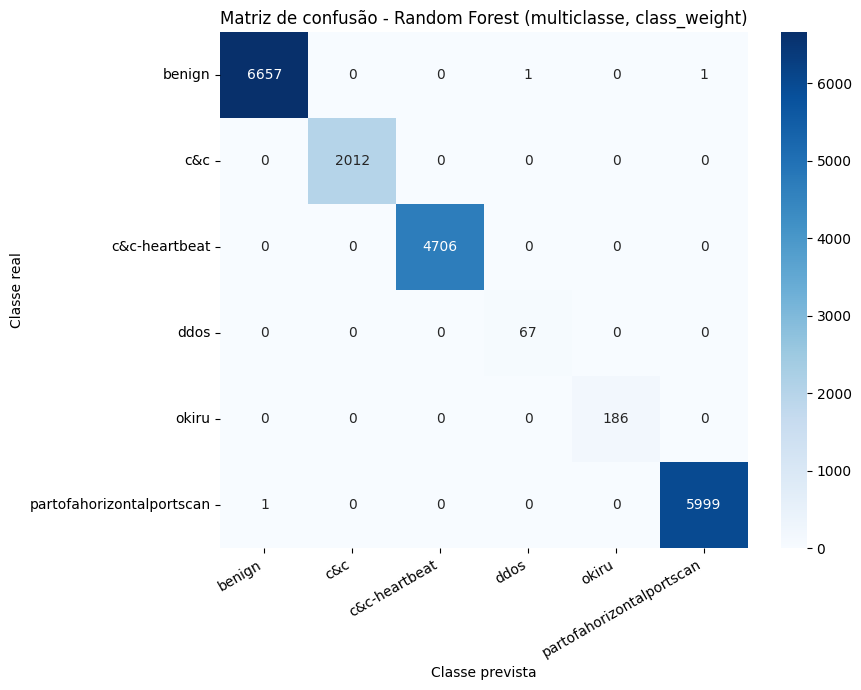

In [ ]:
# Matriz de confusão - RF multiclasse
matriz_rf = plotar_matriz_confusao(
    y_multi_teste, y_pred_multi, rf_multi_cw.classes_,
    "Matriz de confusão - Random Forest (multiclasse, class_weight)",
    "matriz_confusao_rf_multiclasse.png"
)

In [ ]:
# SVM binário - dados originais + class_weight='balanced'
svm_binario_cw = SVC(
    kernel="rbf",
    class_weight="balanced",
    random_state=42
)
svm_binario_cw, y_pred_svm_cw, tempo_treino_svm_cw = treinar_avaliar(
    "SVM (binário) - class_weight",
    svm_binario_cw, X_treino_norm, y_bin_treino, X_teste_norm, y_bin_teste
)

Tempo de treino: 9.03s

=== SVM (binário) - class_weight ===
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00      6659
   malicious       1.00      1.00      1.00     12971

    accuracy                           1.00     19630
   macro avg       1.00      1.00      1.00     19630
weighted avg       1.00      1.00      1.00     19630



In [ ]:
# SVM binário - dados com SMOTE
svm_binario_smote = SVC(
    kernel="rbf",
    random_state=42
    # sem class_weight - o SMOTE já balanceou os dados fisicamente
)
svm_binario_smote, y_pred_svm_smote, tempo_treino_svm_smote = treinar_avaliar(
    "SVM (binário) - SMOTE",
    svm_binario_smote, X_treino_smote_bin, y_bin_treino_smote, X_teste_norm, y_bin_teste
)

Tempo de treino: 10.41s

=== SVM (binário) - SMOTE ===
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00      6659
   malicious       1.00      1.00      1.00     12971

    accuracy                           1.00     19630
   macro avg       1.00      1.00      1.00     19630
weighted avg       1.00      1.00      1.00     19630



In [ ]:
# SVM multiclasse - dados originais + class_weight='balanced'
# (sem SMOTE, mesma decisão do RF multiclasse: okiru e ddos são pequenas demais para sintetizar exemplos com confiança)
svm_multi_cw = SVC(
    kernel="rbf",
    class_weight="balanced",
    random_state=42
)
svm_multi_cw, y_pred_svm_multi, tempo_treino_svm_multi = treinar_avaliar(
    "SVM (multiclasse) - class_weight",
    svm_multi_cw, X_treino_norm, y_multi_treino, X_teste_norm, y_multi_teste
)

Tempo de treino: 18.90s

=== SVM (multiclasse) - class_weight ===
                           precision    recall  f1-score   support

                   benign       1.00      1.00      1.00      6659
                      c&c       1.00      1.00      1.00      2012
            c&c-heartbeat       1.00      1.00      1.00      4706
                     ddos       0.70      0.46      0.56        67
                    okiru       1.00      1.00      1.00       186
partofahorizontalportscan       0.99      1.00      0.99      6000

                 accuracy                           1.00     19630
                macro avg       0.95      0.91      0.93     19630
             weighted avg       1.00      1.00      1.00     19630



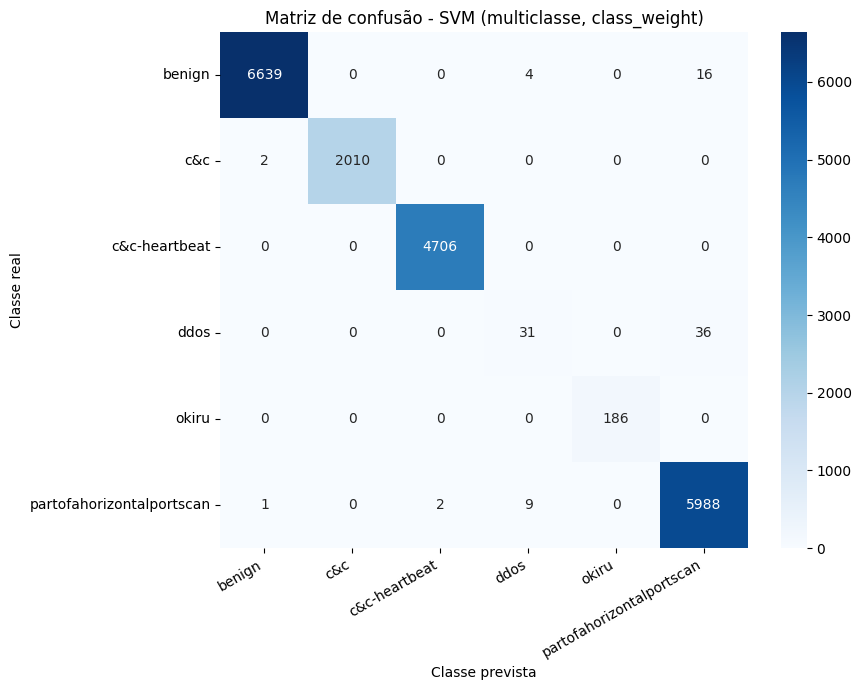

In [ ]:
# Matriz de confusão - SVM multiclasse
matriz_svm = plotar_matriz_confusao(
    y_multi_teste, y_pred_svm_multi, svm_multi_cw.classes_,
    "Matriz de confusão - SVM (multiclasse, class_weight)",
    "matriz_confusao_svm_multiclasse.png"
)

In [ ]:
# Árvore de decisão binária - dados originais + class_weight='balanced'
dt_binario_cw = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42
)
dt_binario_cw, y_pred_dt_cw, tempo_treino_dt_cw = treinar_avaliar(
    "Árvore de Decisão (binário) - class_weight",
    dt_binario_cw, X_treino_norm, y_bin_treino, X_teste_norm, y_bin_teste,
    decimais_tempo=4
)

Tempo de treino: 0.3470s

=== Árvore de Decisão (binário) - class_weight ===
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00      6659
   malicious       1.00      1.00      1.00     12971

    accuracy                           1.00     19630
   macro avg       1.00      1.00      1.00     19630
weighted avg       1.00      1.00      1.00     19630



In [ ]:
# Árvore de decisão binária - dados com SMOTE
dt_binario_smote = DecisionTreeClassifier(
    random_state=42
    # sem class_weight - o SMOTE já balanceou os dados fisicamente
)
dt_binario_smote, y_pred_dt_smote, tempo_treino_dt_smote = treinar_avaliar(
    "Árvore de Decisão (binário) - SMOTE",
    dt_binario_smote, X_treino_smote_bin, y_bin_treino_smote, X_teste_norm, y_bin_teste,
    decimais_tempo=4
)

Tempo de treino: 0.3884s

=== Árvore de Decisão (binário) - SMOTE ===
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00      6659
   malicious       1.00      1.00      1.00     12971

    accuracy                           1.00     19630
   macro avg       1.00      1.00      1.00     19630
weighted avg       1.00      1.00      1.00     19630



In [ ]:
# Árvore de decisão multiclasse - dados originais + class_weight='balanced'
# (sem SMOTE, mesma decisão já tomada para RF e SVM multiclasse)
dt_multi_cw = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42
)
dt_multi_cw, y_pred_dt_multi, tempo_treino_dt_multi = treinar_avaliar(
    "Árvore de Decisão (multiclasse) - class_weight",
    dt_multi_cw, X_treino_norm, y_multi_treino, X_teste_norm, y_multi_teste,
    decimais_tempo=4
)

Tempo de treino: 0.2908s

=== Árvore de Decisão (multiclasse) - class_weight ===
                           precision    recall  f1-score   support

                   benign       1.00      1.00      1.00      6659
                      c&c       1.00      1.00      1.00      2012
            c&c-heartbeat       1.00      1.00      1.00      4706
                     ddos       1.00      1.00      1.00        67
                    okiru       1.00      1.00      1.00       186
partofahorizontalportscan       1.00      1.00      1.00      6000

                 accuracy                           1.00     19630
                macro avg       1.00      1.00      1.00     19630
             weighted avg       1.00      1.00      1.00     19630



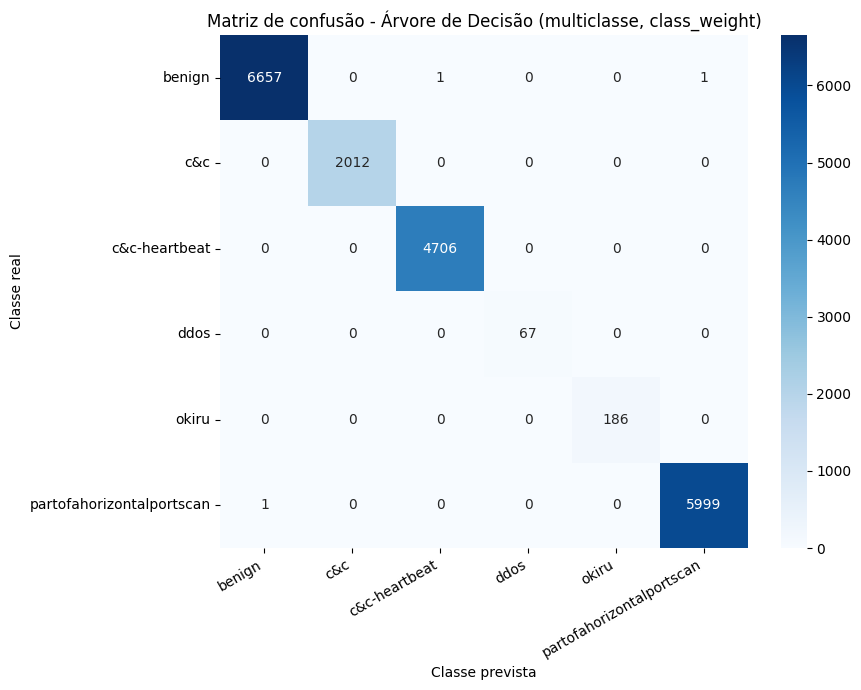

In [ ]:
# Matriz de confusão - Árvore de Decisão multiclasse
matriz_ad = plotar_matriz_confusao(
    y_multi_teste, y_pred_dt_multi, dt_multi_cw.classes_,
    "Matriz de confusão - Árvore de Decisão (multiclasse, class_weight)",
    "matriz_confusao_dt_multiclasse.png"
)

In [ ]:
# Outras métricas
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

modelos_para_cv = [
    ("Random Forest - binário", rf_binario_cw, X_treino_norm, y_bin_treino),
    ("Random Forest - multiclasse", rf_multi_cw, X_treino_norm, y_multi_treino),
    ("SVM - binário", svm_binario_cw, X_treino_norm, y_bin_treino),
    ("SVM - multiclasse", svm_multi_cw, X_treino_norm, y_multi_treino),
    ("Árvore de Decisão - binário", dt_binario_cw, X_treino_norm, y_bin_treino),
    ("Árvore de Decisão - multiclasse", dt_multi_cw, X_treino_norm, y_multi_treino),
]

resultados_cv = []
for nome, modelo, X, y in modelos_para_cv:
    inicio = time.time()
    scores = cross_val_score(modelo, X, y, cv=cv, scoring="f1_macro", n_jobs=-1)
    tempo_cv = time.time() - inicio
    resultados_cv.append({
        "modelo": nome,
        "f1_macro_medio": scores.mean(),
        "f1_macro_desvio": scores.std(),
        "tempo_total_s": round(tempo_cv, 1),
    })
    print(f"{nome}: F1-macro = {scores.mean():.4f} ± {scores.std():.4f}  "
          f"(folds: {[round(s, 4) for s in scores]}, {tempo_cv:.1f}s)")

df_resultados_cv = pd.DataFrame(resultados_cv)
df_resultados_cv


Random Forest - binário: F1-macro = 0.9997 ± 0.0002  (folds: [np.float64(0.9995), np.float64(1.0), np.float64(0.9995), np.float64(0.9996), np.float64(0.9999)], 10.5s)
Random Forest - multiclasse: F1-macro = 0.9944 ± 0.0017  (folds: [np.float64(0.9934), np.float64(0.9973), np.float64(0.9924), np.float64(0.9945), np.float64(0.9943)], 9.5s)
SVM - binário: F1-macro = 0.9986 ± 0.0007  (folds: [np.float64(0.9976), np.float64(0.9996), np.float64(0.9984), np.float64(0.9982), np.float64(0.9991)], 27.7s)
SVM - multiclasse: F1-macro = 0.9262 ± 0.0232  (folds: [np.float64(0.885), np.float64(0.9265), np.float64(0.9303), np.float64(0.9567), np.float64(0.9326)], 75.1s)
Árvore de Decisão - binário: F1-macro = 0.9998 ± 0.0002  (folds: [np.float64(0.9999), np.float64(1.0), np.float64(0.9995), np.float64(0.9999), np.float64(0.9999)], 1.2s)
Árvore de Decisão - multiclasse: F1-macro = 0.9954 ± 0.0034  (folds: [np.float64(0.9972), np.float64(0.999), np.float64(0.9943), np.float64(0.9893), np.float64(0.9972)

,modelo,f1_macro_medio,f1_macro_desvio,tempo_total_s
0,Random Forest - binário,0.999708,0.000198,10.5
1,Random Forest - multiclasse,0.994387,0.001653,9.5
2,SVM - binário,0.998587,0.000730,27.7
3,SVM - multiclasse,0.926223,0.023180,75.1
4,Árvore de Decisão - binário,0.999830,0.000165,1.2
5,Árvore de Decisão - multiclasse,0.995403,0.003409,1.1


In [ ]:
# Métricas de inferência

N_REPETICOES = 10

modelos_para_inferencia = [
    ("Random Forest - binário (class_weight)", rf_binario_cw, X_teste_norm),
    ("Random Forest - binário (SMOTE)", rf_binario_smote, X_teste_norm),
    ("Random Forest - multiclasse (class_weight)", rf_multi_cw, X_teste_norm),
    ("SVM - binário (class_weight)", svm_binario_cw, X_teste_norm),
    ("SVM - binário (SMOTE)", svm_binario_smote, X_teste_norm),
    ("SVM - multiclasse (class_weight)", svm_multi_cw, X_teste_norm),
    ("Árvore de Decisão - binário (class_weight)", dt_binario_cw, X_teste_norm),
    ("Árvore de Decisão - binário (SMOTE)", dt_binario_smote, X_teste_norm),
    ("Árvore de Decisão - multiclasse (class_weight)",  dt_multi_cw, X_teste_norm),
]

resultados_inferencia = []
for nome, modelo, X in modelos_para_inferencia:
    tempos_ms_por_amostra = []
    for _ in range(N_REPETICOES):
        inicio = time.perf_counter()
        modelo.predict(X)
        fim = time.perf_counter()
        tempos_ms_por_amostra.append((fim - inicio) / len(X) * 1000)

    media = np.mean(tempos_ms_por_amostra)
    desvio = np.std(tempos_ms_por_amostra)
    resultados_inferencia.append({
        "modelo": nome,
        "tempo_medio_ms_amostra": media,
        "tempo_desvio_ms_amostra": desvio,
    })
    print(f"{nome}: {media:.5f} ± {desvio:.5f} ms/amostra")

df_resultados_inferencia = pd.DataFrame(resultados_inferencia)
df_resultados_inferencia

Random Forest - binário (class_weight): 0.00422 ± 0.00028 ms/amostra
Random Forest - binário (SMOTE): 0.00417 ± 0.00033 ms/amostra
Random Forest - multiclasse (class_weight): 0.00509 ± 0.00019 ms/amostra
SVM - binário (class_weight): 0.03150 ± 0.00721 ms/amostra
SVM - binário (SMOTE): 0.02629 ± 0.00084 ms/amostra
SVM - multiclasse (class_weight): 0.68316 ± 0.01652 ms/amostra
Árvore de Decisão - binário (class_weight): 0.00025 ± 0.00003 ms/amostra
Árvore de Decisão - binário (SMOTE): 0.00022 ± 0.00001 ms/amostra
Árvore de Decisão - multiclasse (class_weight): 0.00025 ± 0.00001 ms/amostra


,modelo,tempo_medio_ms_amostra,tempo_desvio_ms_amostra
0,Random Forest - binário (class_weight),0.004221,0.000281
1,Random Forest - binário (SMOTE),0.004169,0.000332
2,Random Forest - multiclasse (class_weight),0.005088,0.000194
3,SVM - binário (class_weight),0.031495,0.007205
4,SVM - binário (SMOTE),0.026291,0.000838
5,SVM - multiclasse (class_weight),0.683158,0.016522
6,Árvore de Decisão - binário (class_weight),0.000251,0.000030
7,Árvore de Decisão - binário (SMOTE),0.000224,0.000008
8,Árvore de Decisão - multiclasse (class_weight),0.000250,0.000005
